# Lab 04 · Part 3 — Comparing the approaches

Reads the results saved by notebooks 1 and 2 (`results/*.json`) and puts all
five ways of adapting `SmolLM2-135M-Instruct` to ticket triage side by side.
Nothing is trained here.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = Path("results")
prompting = json.load(open(RESULTS / "prompting.json"))
runs = pd.DataFrame(json.load(open(RESULTS / "finetune.json")))
quant_df = pd.DataFrame(json.load(open(RESULTS / "quantization.json")))
few = pd.DataFrame(prompting["few_shot"])
zs = prompting["zero_shot"]

## One table

Accuracy / macro-F1 on the 100 held-out tickets (mean ± std over seeds).
Few-shot uses `k = 4` tickets per category in the prompt; the trained methods use
20 per category. *Trainable* is the number of weights the method updates,
*shipped* is the size of what you would have to save to deploy the fine-tune.

In [2]:
def pm(series):
    return f"{series.mean():.3f} ± {series.std():.3f}"

main = runs[(runs.n_per_class == 20) & (runs.r == 8) & (runs.epochs == 5)
            & (runs.bits.isna() | (runs.bits == 4))]
rows = [
    {"method": "zero-shot", "accuracy": f"{zs['accuracy']:.3f}", "macro_F1": f"{zs['macro_f1']:.3f}",
     "trainable": 0, "shipped": "0", "prompt_tokens": f"{zs['prompt_tokens']:.0f}",
     "sec/ticket": f"{zs['sec_per_ticket']:.2f}", "general_ppl": f"{prompting['base_general_ppl']:.1f}"},
]
k4 = few[few.k == 4]
rows.append({"method": "few-shot (k=4)", "accuracy": pm(k4.accuracy), "macro_F1": pm(k4.macro_f1),
             "trainable": 0, "shipped": "0", "prompt_tokens": f"{k4.prompt_tokens.mean():.0f}",
             "sec/ticket": f"{k4.sec_per_ticket.mean():.2f}", "general_ppl": f"{prompting['base_general_ppl']:.1f}"})
names = {"full": "full fine-tuning", "lora": "LoRA (r=8)", "qlora": "QLoRA (NF4, r=8)"}
for method in ["full", "lora", "qlora"]:
    g = main[main.method == method]
    rows.append({"method": names[method], "accuracy": pm(g.accuracy), "macro_F1": pm(g.macro_f1),
                 "trainable": f"{int(g.trainable_params.iloc[0]):,}",
                 "shipped": f"{g.checkpoint_bytes.iloc[0] / 1e6:.1f} MB",
                 "prompt_tokens": f"{zs['prompt_tokens']:.0f}",
                 "sec/ticket": f"{g.sec_per_ticket.mean():.2f}", "general_ppl": f"{g.general_ppl.mean():.1f}"})
table = pd.DataFrame(rows)
table

,method,accuracy,macro_F1,trainable,shipped,prompt_tokens,sec/ticket,general_ppl
0,zero-shot,0.440,0.412,0,0,57,0.01,32.3
1,few-shot (k=4),0.453 ± 0.192,0.406 ± 0.206,0,0,513,0.05,32.3
2,full fine-tuning,0.903 ± 0.006,0.904 ± 0.006,"106,203,456",424.8 MB,57,0.01,32.6
3,LoRA (r=8),0.900 ± 0.026,0.900 ± 0.026,"921,600",3.8 MB,57,0.01,33.2
4,"QLoRA (NF4, r=8)",0.937 ± 0.015,0.936 ± 0.015,"921,600",3.8 MB,57,0.02,38.9


## Accuracy vs. number of labelled tickets

The same budget of labelled examples can go **into the prompt** (few-shot, no
training) or **into the weights** (LoRA). Dashed line: zero-shot, 0 examples.

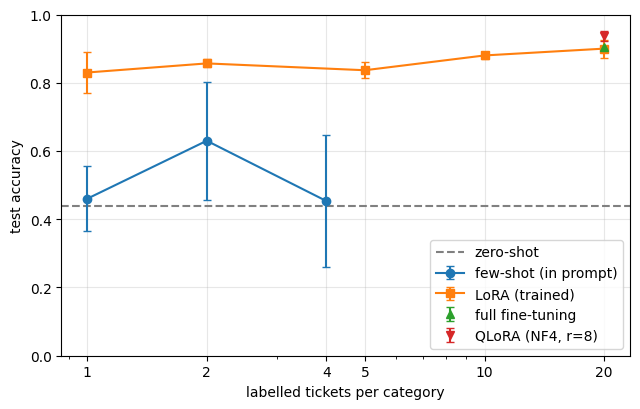

In [3]:
lora_n = runs[(runs.method == "lora") & (runs.r == 8) & (runs.epochs == 5)]
g_lora = lora_n.groupby("n_per_class").accuracy.agg(["mean", "std"])
g_few = few.groupby("k").accuracy.agg(["mean", "std"])

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.axhline(zs["accuracy"], color="gray", ls="--", label="zero-shot")
ax.errorbar(g_few.index, g_few["mean"], g_few["std"], marker="o", capsize=3, label="few-shot (in prompt)")
ax.errorbar(g_lora.index, g_lora["mean"], g_lora["std"], marker="s", capsize=3, label="LoRA (trained)")
for method, marker in [("full", "^"), ("qlora", "v")]:
    g = main[main.method == method].accuracy
    ax.errorbar([20], [g.mean()], [g.std()], marker=marker, capsize=3, ls="none", label=names[method])
ax.set_xscale("log")
ax.set_xticks([1, 2, 4, 5, 10, 20])
ax.set_xticklabels([1, 2, 4, 5, 10, 20])
ax.set_xlabel("labelled tickets per category")
ax.set_ylabel("test accuracy")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS / "accuracy_vs_examples.png", dpi=120)
plt.show()

## LoRA rank

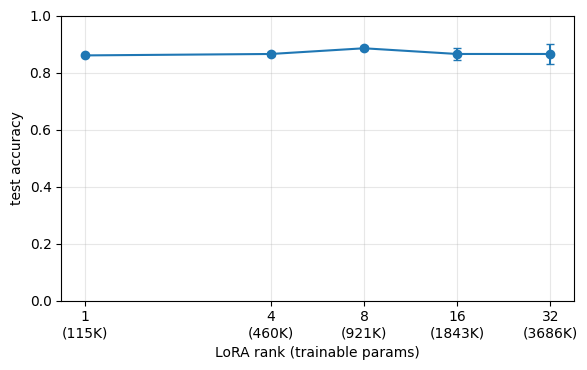

In [4]:
rank = runs[(runs.method == "lora") & (runs.n_per_class == 10) & runs.seed.isin([0, 1]) & (runs.epochs == 5)]
g = rank.groupby("r").agg(acc=("accuracy", "mean"), std=("accuracy", "std"),
                          trainable=("trainable_params", "first"))
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.errorbar(g.index, g.acc, g["std"], marker="o", capsize=3)
ax.set_xscale("log", base=2)
ax.set_xticks(g.index)
ax.set_xticklabels([f"{r}\n({int(t / 1e3)}K)" for r, t in zip(g.index, g.trainable)])
ax.set_xlabel("LoRA rank (trainable params)")
ax.set_ylabel("test accuracy")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS / "lora_rank.png", dpi=120)
plt.show()

## Memory: what each method has to hold while training

Rough numbers from parameter counts. Training with AdamW holds, per trainable
weight, a gradient plus two optimizer moments (3 × 4 bytes in fp32). The frozen
base weights only need to be stored. Activations are ignored here (they depend on
batch size and prompt length and are the same for every method).

,method,decoder_weights_MB,grads+Adam_MB,total_MB,checkpoint_MB
0,full fine-tuning,424.8,1274.4,1699.3,424.81
1,LoRA (r=8),428.5,11.1,439.6,3.76
2,"QLoRA (NF4, r=8)",63.5,11.1,74.6,3.76


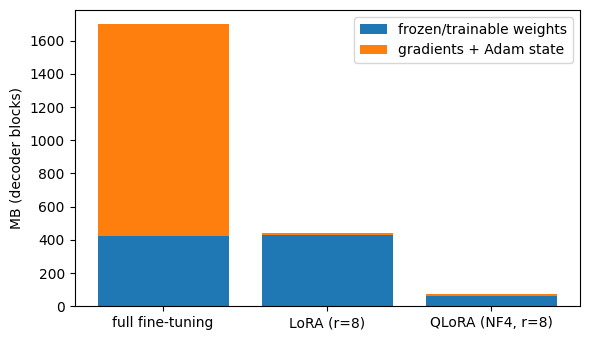

In [5]:
rows = []
for method in ["full", "lora", "qlora"]:
    g = main[main.method == method].iloc[0]
    base_mb = g.base_weight_bytes / 1e6
    train_mb = g.trainable_params * 12 / 1e6
    rows.append({"method": names[method], "decoder_weights_MB": round(base_mb, 1),
                 "grads+Adam_MB": round(train_mb, 1),
                 "total_MB": round(base_mb + train_mb, 1),
                 "checkpoint_MB": round(g.checkpoint_bytes / 1e6, 2)})
mem = pd.DataFrame(rows)
display(mem)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(mem.method, mem.decoder_weights_MB, label="frozen/trainable weights")
ax.bar(mem.method, mem["grads+Adam_MB"], bottom=mem.decoder_weights_MB, label="gradients + Adam state")
ax.set_ylabel("MB (decoder blocks)")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "memory.png", dpi=120)
plt.show()

## Quantization cost and recovery (QLoRA)

In [6]:
q = main[main.method == "qlora"]
print(f"QLoRA, accuracy right after 4-bit quantization, before training: "
      f"{q.acc_after_quant_before_train.mean():.3f}  (fp32 zero-shot: {zs['accuracy']:.3f})")
print(f"QLoRA, accuracy after training the LoRA adapters:                {q.accuracy.mean():.3f}")
quant_df.round(3)

QLoRA, accuracy right after 4-bit quantization, before training: 0.230  (fp32 zero-shot: 0.440)
QLoRA, accuracy after training the LoRA adapters:                0.937


,setting,accuracy,general_ppl,decoder_MB
0,fp32 (original),0.44,32.274,424.812
1,8-bit quantized,0.45,32.346,116.628
2,4-bit quantized,0.23,38.910,63.544


## Per-seed results

In [7]:
runs[["method", "n_per_class", "r", "seed", "accuracy", "macro_f1", "general_ppl", "train_sec"]].round(3)

,method,n_per_class,r,seed,accuracy,macro_f1,general_ppl,train_sec
0,full,20,8,0,0.90,0.900,32.522,15.160
1,lora,20,8,0,0.88,0.879,32.933,17.272
2,qlora,20,8,0,0.92,0.920,39.140,23.116
3,full,20,8,1,0.90,0.901,32.558,15.573
4,lora,20,8,1,0.89,0.892,33.676,17.613
5,qlora,20,8,1,0.94,0.939,38.793,22.974
6,full,20,8,2,0.91,0.910,32.583,13.515
7,lora,20,8,2,0.93,0.929,32.920,12.331
8,qlora,20,8,2,0.95,0.950,38.761,15.902
9,lora,1,8,0,0.87,0.870,32.647,0.916


## Takeaways

| | zero-shot | few-shot | full FT | LoRA | QLoRA |
|---|---|---|---|---|---|
| weights change | no | no | yes (106M) | yes (0.9M) | yes (0.9M) |
| labelled data used | 0 | 5-20 in the prompt | 100 | 100 | 100 |
| accuracy | 44% | 45% (very noisy) | 90% | 90% | 94% |
| training memory (est.) | - | - | ~1.7 GB | ~0.44 GB | ~0.07 GB |
| what you ship | nothing | the examples | 425 MB | 3.8 MB | 3.8 MB (+ the 4-bit base) |

* On this task, putting labelled examples into the weights beat putting them into the prompt by a wide margin,
  and needed fewer of them (5 tickets with LoRA beat 20 in the prompt).
* LoRA matched full fine-tuning at 1/100 of the trainable parameters and ~1/110 of the shipped size.
* QLoRA cuts the frozen base to ~15% of fp32 size, at the price of a worse starting model and a slower step
  (it dequantizes every layer on every forward pass: ~21 s vs ~16 s per run here, on the GPU).

**Caveats.** One small model (135M), one hand-written 5-class dataset, 100 test tickets and 2-3 seeds, so
differences of a few points are noise. The memory figures are estimated from parameter counts
(weights + gradients + Adam state) and ignore activations. Prompting was scored with the same next-token
read-out as everything else, which suits fine-tuning (it trains exactly that read-out), and probably
flatters it relative to few-shot prompting with free-text generation.